# Chart 1: Average U.S. regular retail gasoline price, by administration (nominal)

Article: <https://www.dailysignal.com/2026/09/30/real-story-gas-prices/> (Sanjai Bhagat, The Daily Signal, 30 Sep 2026).

Replicates the article's first chart: the average monthly retail price of regular gasoline during each of the last four administrations, in the dollars of the day. Cited source: www.eia.gov, series `EMM_EPMR_PTE_NUS_DPG` (U.S. Regular All Formulations Retail Gasoline Prices, monthly, dollars per gallon).

Shared pieces live in two modules: `fetch_data.py` checks whether the local data is current and downloads it if not;
`charts.py` holds the styling, the administration windows and the chart helpers. The rendered PNG is written to `output/`.

## Data currency check

Only the sources this chart needs are checked. Stale or missing copies are downloaded; current ones are left alone.

In [1]:
import fetch_data

statuses = fetch_data.refresh(['eia_gasoline'])

eia_gasoline   current    latest=2026-09-01 fetched=2026-10-06T20:52:21+00:00


## Load the data

In [2]:
import polars as pl
import charts

gas = fetch_data.load("eia_gasoline")  # date, price_usd_per_gal
print(f"{gas['date'].min()} .. {gas['date'].max()}  ({gas.height} months)")
gas.tail(3)

1990-09-01 .. 2026-09-01  (431 months)


date,price_usd_per_gal
date,f64
2026-07-01,3.932
2026-08-01,4.058
2026-09-01,4.355


## Administration windows

January of the inauguration year through December of the last full year; Trump 2.0 runs through August 2026 as in the article.
Set `EXTEND_TO_LATEST = True` to run it through the newest month of EIA data instead.

In [3]:
EXTEND_TO_LATEST = False

admins = dict(charts.ADMINS)
if EXTEND_TO_LATEST:
    admins["Trump 2.0"] = (admins["Trump 2.0"][0], gas["date"].max())
admins

{'Obama': (datetime.date(2009, 1, 1), datetime.date(2016, 12, 1)),
 'Trump 1.0': (datetime.date(2017, 1, 1), datetime.date(2020, 12, 1)),
 'Biden': (datetime.date(2021, 1, 1), datetime.date(2024, 12, 1)),
 'Trump 2.0': (datetime.date(2025, 1, 1), datetime.date(2026, 8, 1))}

## Chart

administration,recomputed,article
str,f64,f64
"""Obama""",2.96,2.96
"""Trump 1.0""",2.48,2.48
"""Biden""",3.45,3.45
"""Trump 2.0""",3.36,3.36


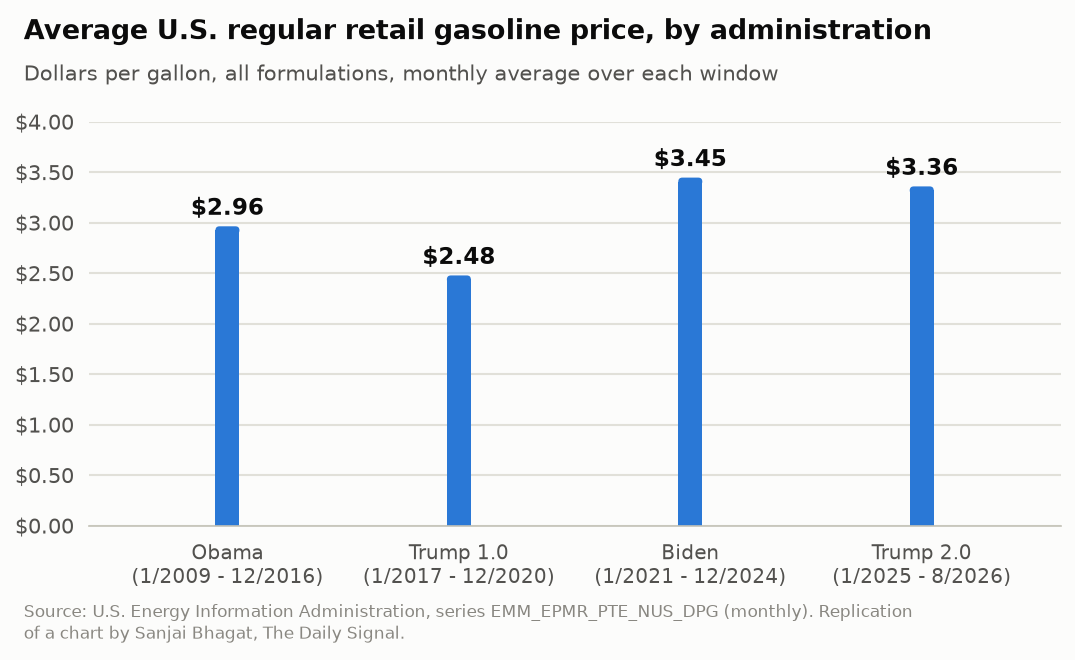

In [4]:
nominal = charts.period_mean(gas, "price_usd_per_gal", admins)
ARTICLE = [2.96, 2.48, 3.45, 3.36]

charts.bar_chart(
    charts.admin_labels(admins), nominal,
    title="Average U.S. regular retail gasoline price, by administration",
    subtitle="Dollars per gallon, all formulations, monthly average over each window",
    source="Source: U.S. Energy Information Administration, series EMM_EPMR_PTE_NUS_DPG (monthly). Replication of a chart by Sanjai Bhagat, The Daily Signal.",
    fmt=lambda v: f"${v:,.2f}", ymax=4.0, ystep=0.5, fname="01_gas_price_nominal.png",
)
charts.compare(admins, nominal, ARTICLE)

## Notes

The recomputed averages reproduce the article's figures exactly. The visual style is a single-hue, thin-bar design rather than the Excel defaults of the original; title, windows, units and source are preserved.